<a href="https://colab.research.google.com/github/Mohsi777999/Machine-Learning-Labs/blob/main/Lab_03_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**By Mohsin Ali**

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")

## 2. Load Dataset
We load the **Breast Cancer Dataset** from `sklearn.datasets` and construct a pandas DataFrame for easier analysis.

In [2]:
# Load dataset
data = load_breast_cancer()

# Convert to DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print(f"Dataset shape: {df.shape}")

Dataset shape: (569, 31)


## 3. Exploratory Data Analysis (EDA)
* Displaying the first few rows.
* Checking for missing values.
* Plotting distributions and verifying target class balance.

In [3]:
# Display the first 5 rows
display(df.head())

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


Class Distribution (Malignant vs Benign):
Benign       357
Malignant    212
Name: count, dtype: int64


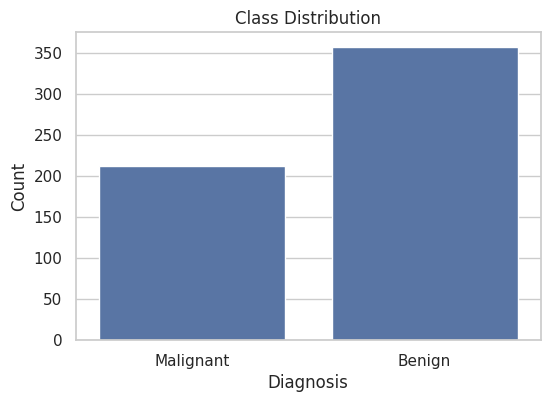

In [5]:
# Class distribution
print("Class Distribution (Malignant vs Benign):")
# 0 = Malignant, 1 = Benign
classes = pd.Series(data.target).map({0: 'Malignant', 1: 'Benign'})
print(classes.value_counts())

# Visualizing Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=classes)
plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

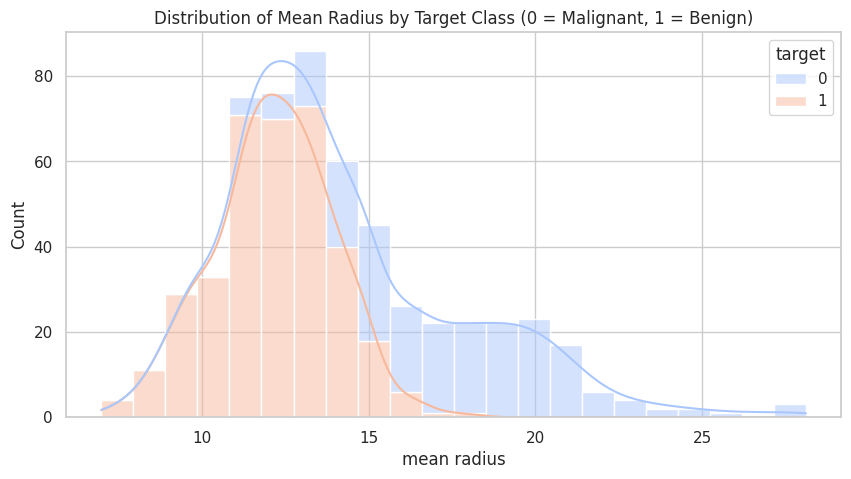

In [6]:
# Distribution of features (e.g., mean radius)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='mean radius', hue='target', kde=True, multiple='stack', palette='coolwarm')
plt.title("Distribution of Mean Radius by Target Class (0 = Malignant, 1 = Benign)")
plt.show()

## 4. Data Preprocessing
* Split features (X) and labels (y).
* Split into Training and Testing subsets.
* Standardize the features so the gradient descent optimizer converges efficiently.

In [7]:
# Split features and labels
X = df.drop(columns=['target'])
y = df['target']

# Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


## 5. Model Implementation
We instantiate and train a standard `LogisticRegression` classifier on our scaled training set.

In [8]:
# Initialize the Logistic Regression model
model = LogisticRegression(random_state=42)

# Train the model
model.fit(X_train_scaled, y_train)

# Predict on the test data
y_pred = model.predict(X_test_scaled)

print("Training completed!")

Training completed!


## 6. Model Evaluation
Evaluating the model performance using Accuracy, Confusion Matrix, and Precision/Recall/F1-Score.

Model Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



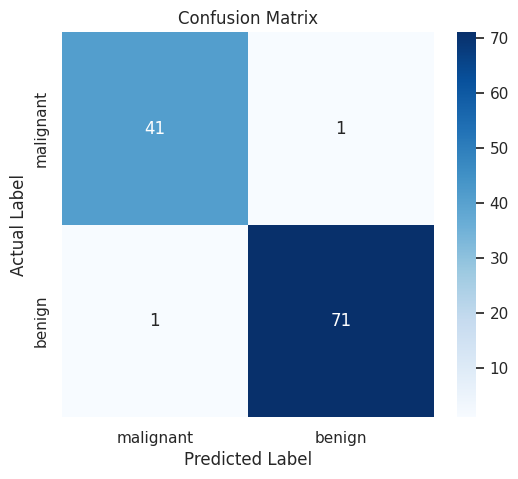

In [9]:
# Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
plt.title("Confusion Matrix")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.show()